# 🍽️ Concierge · CRISP-DM | 03b · Data Preparation e Modeling com a nota individual

**Grupo:** Fabrício Wenter, Gabriel Gandolfi, Luís Gustavo Barbosa e Murilo Pilão

**Pergunta de negócio:** este consumidor vai **gostar** deste restaurante (nota 4 ou 5) antes de pedir ou reservar?
Se sim, o restaurante pode entrar no top 5 diário.

**Como o notebook responde**
1. Dados: Yelp Open Dataset real (`business` + `review` em `data/raw/`) ou amostra sintética com o mesmo esquema
2. Preparação sem vazamento: atributos calculados **só com o passado** de cada avaliação
3. Corte temporal: treino até 2018, validação em 2019, teste a partir de 2020
4. Modelos: baselines de popularidade, **regressão logística, árvore de decisão, random forest, gradient boosting e KNN**
5. Avaliação: **% de acertos, falsos positivos e falsos negativos**, com o limiar escolhido pelo custo do erro
6. KPI técnico do BU: **RMSE da nota** contra a média global e a lista por popularidade
7. Uso: top 5 para um perfil declarado no questionário

**Custo do erro (BU, 1.2):** o **falso positivo** (recomendar algo de que a pessoa não gosta) é o erro caro, porque
96% não voltam a um restaurante que frustrou. O falso negativo é oportunidade perdida, sem dano. Por isso o limiar de
decisão privilegia a **precisão**.

**Ordem de execução:** rode depois do `03a_modeling_yelp.ipynb`. O 03a gera o modelo usado no app; este notebook
responde à pergunta original do BU (nota que **cada pessoa** dá a **cada restaurante**), que só o `review.json`
permite, e serve de comparação. Com o Yelp real, a leitura do `review.json` (≈5 GB) leva alguns minutos.

In [1]:
import ast
import json
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, fbeta_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
SEED = 42

# Raiz do repositório: funciona rodando de notebooks/ ou da raiz
RAIZ = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "src" / "concierge").exists()), Path.cwd())
# O Yelp real fica em data/raw/ (fora do Git). YELP_DIR permite apontar outra pasta, ex.: dados de teste.
PASTAS_YELP = [Path(os.environ["YELP_DIR"])] if os.environ.get("YELP_DIR") else [RAIZ / "data" / "raw"]
SAIDA = RAIZ / "reports" / "03b_reviews"
MODELOS = RAIZ / "models"
SAIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(exist_ok=True)
CIDADE = "Philadelphia"

## 1. Dados

**Ordem de preferência** (igual ao `load_yelp.py` do repositório):
1. **Yelp Open Dataset real.** É público e gratuito para uso acadêmico, mas exige aceitar os termos em
   <https://www.yelp.com/dataset> (≈9 GB). Basta ter `yelp_academic_dataset_business.json` e
   `yelp_academic_dataset_review.json` em `data/raw/` (o `user.json` não é usado: `average_stars` é snapshot). A leitura
   é em blocos, guarda só as colunas usadas e já filtra Philadelphia + categoria *Restaurants*. Se existir o
   `review_philadelphia.json.gz` gerado por `scripts/filtrar_reviews.py`, ele é lido no lugar do arquivo de 5 GB.
2. **Amostra sintética** com o mesmo esquema e a mesma semente do `src/concierge/synthetic.py` (≈1.500 restaurantes,
   ≈40 mil avaliações). Ela embute cauda longa, matriz esparsa, notas concentradas em 4 e 5 e gosto latente por
   culinária e preço. Os números servem para validar o código; com o Yelp real, o mesmo notebook recalcula tudo.

In [2]:
# ============ gerador sintético (cópia de src/concierge/synthetic.py, mesma semente) ============
CULINARIAS = {
    "Pizza": (0.12, 1.4), "American": (0.14, 2.0), "Italian": (0.09, 2.5), "Chinese": (0.09, 1.6),
    "Mexican": (0.08, 1.6), "Japanese": (0.06, 2.6), "Sandwiches": (0.08, 1.3),
    "Breakfast & Brunch": (0.06, 1.8), "Burgers": (0.06, 1.6), "Thai": (0.04, 1.9),
    "Indian": (0.03, 2.0), "Mediterranean": (0.03, 2.1), "Vegan": (0.02, 2.0),
    "Seafood": (0.03, 2.9), "Steakhouses": (0.02, 3.6), "Korean": (0.02, 2.2),
    "Vietnamese": (0.03, 1.5),
}
BAIRROS = {
    "Center City": (39.9526, -75.1652), "Old City": (39.9522, -75.1440), "Fishtown": (39.9727, -75.1340),
    "South Philly": (39.9245, -75.1690), "University City": (39.9522, -75.1932),
    "Northern Liberties": (39.9637, -75.1406), "Manayunk": (40.0262, -75.2245),
    "Chinatown": (39.9555, -75.1550),
}


def gerar_restaurantes(n, rng):
    nomes_cul = list(CULINARIAS)
    pesos = np.array([CULINARIAS[c][0] for c in nomes_cul]); pesos = pesos / pesos.sum()
    linhas = []
    for i in range(n):
        cul = rng.choice(nomes_cul, p=pesos)
        preco = int(np.clip(np.round(rng.normal(CULINARIAS[cul][1], 0.6)), 1, 4))
        bairro = rng.choice(list(BAIRROS)); lat0, lon0 = BAIRROS[bairro]
        extras = rng.choice(["Restaurants", "Food", "Bars", "Nightlife", "Coffee & Tea", "Fast Food", "Delis"],
                            size=rng.integers(1, 3), replace=False).tolist()
        categorias = ", ".join(dict.fromkeys([cul, "Restaurants"] + extras))
        attrs = {}
        if rng.random() > 0.13:
            attrs["RestaurantsPriceRange2"] = str(preco) if rng.random() > 0.02 else "None"
        if rng.random() > 0.10:
            attrs["RestaurantsDelivery"] = rng.choice(["True", "False", "None"], p=[.55, .4, .05])
        if rng.random() > 0.15:
            attrs["RestaurantsReservations"] = (
                "True" if (preco >= 3 and rng.random() > .2) or rng.random() > .75 else "False")
        if rng.random() > 0.08:
            attrs["RestaurantsTakeOut"] = rng.choice(["True", "False"], p=[.85, .15])
        if rng.random() > 0.30:
            attrs["WiFi"] = rng.choice(["u'free'", "'free'", "u'no'", "'no'", "None"])
        horario = None if rng.random() < 0.18 else {
            d: "11:0-22:0" for d in ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]}
        linhas.append({
            "business_id": f"b{i:05d}", "name": f"Restaurante {i}",
            "city": "Philadelphia" if rng.random() > 0.01 else "Philadelphia ", "state": "PA",
            "neighborhood_sim": bairro,
            "latitude": lat0 + rng.normal(0, 0.006), "longitude": lon0 + rng.normal(0, 0.006),
            "is_open": int(rng.random() > 0.27), "attributes": attrs or None, "categories": categorias,
            "hours": horario, "_culinaria": cul, "_preco": preco, "_qualidade": rng.normal(0, 0.55),
        })
    return pd.DataFrame(linhas)


def gerar_usuarios_e_reviews(rest, n_users, rng):
    nomes_cul = list(CULINARIAS); idx_cul = {c: k for k, c in enumerate(nomes_cul)}
    cul_rest = rest["_culinaria"].map(idx_cul).to_numpy()
    preco_rest = rest["_preco"].to_numpy(); qual_rest = rest["_qualidade"].to_numpy()
    pop = (rng.pareto(1.3, len(rest)) + 0.05) * np.exp(0.8 * qual_rest)
    afinidade = rng.dirichlet(np.full(len(nomes_cul), 0.35), n_users)
    preco_pref = np.clip(np.round(rng.normal(2.0, 0.8, n_users)), 1, 4)
    vies = rng.normal(0, 0.45, n_users)
    n_reviews = np.clip(rng.zipf(1.9, n_users), 1, 250)
    datas_ini = pd.Timestamp("2012-01-01").value // 10**9
    datas_fim = pd.Timestamp("2022-01-19").value // 10**9
    reviews, usuarios, rid = [], [], 0
    for u in range(n_users):
        p = pop ** 0.7 * (0.02 + afinidade[u, cul_rest]) ** 1.3 * np.exp(-0.6 * np.abs(preco_rest - preco_pref[u]))
        p = p / p.sum()
        k = int(min(n_reviews[u], len(rest)))
        escolhidos = rng.choice(len(rest), size=k, replace=False, p=p)
        inicio = rng.integers(datas_ini, datas_fim - 86400 * 30)
        fim_u = int(min(datas_fim, inicio + 86400 * (30 + rng.exponential(730))))
        notas_u = []
        for b in escolhidos:
            gosto = 6.0 * (afinidade[u, cul_rest[b]] - 1 / len(nomes_cul))
            latente = (3.95 + qual_rest[b] + gosto - 0.35 * abs(preco_rest[b] - preco_pref[u])
                       + vies[u] + rng.normal(0, 0.75))
            nota = int(np.clip(np.round(latente), 1, 5))
            if latente < 2.6 and rng.random() < 0.65:
                nota = 1
            elif latente > 4.3:
                nota = 5
            ts = rng.integers(inicio, fim_u); d = pd.Timestamp(ts, unit="s")
            if (d.year == 2020 and d.month >= 3 and rng.random() < 0.55) or (d.year == 2021 and rng.random() < 0.35):
                continue
            notas_u.append(nota)
            reviews.append({"review_id": f"r{rid:07d}", "user_id": f"u{u:05d}",
                            "business_id": rest.at[b, "business_id"], "stars": float(nota),
                            "useful": int(rng.poisson(0.9)), "funny": int(rng.poisson(0.3)),
                            "cool": int(rng.poisson(0.4)), "text": "(texto omitido na amostra sintética)",
                            "date": d.strftime("%Y-%m-%d %H:%M:%S")})
            rid += 1
        usuarios.append({
            "user_id": f"u{u:05d}", "name": f"Usuario {u}", "review_count": int(k + rng.poisson(k * 0.4)),
            "yelping_since": pd.Timestamp(inicio - rng.integers(0, 86400 * 400), unit="s").strftime("%Y-%m-%d %H:%M:%S"),
            "useful": int(rng.poisson(k * 1.5)), "fans": int(rng.poisson(k * 0.05)),
            "average_stars": round(float(np.mean(notas_u) if notas_u else rng.normal(3.8, 0.6)) + rng.normal(0, 0.1), 2),
            "elite": "" if rng.random() > 0.04 else "2018,2019"})
    reviews = pd.DataFrame(reviews)
    reviews = pd.concat([reviews, reviews.sample(frac=0.002, random_state=SEED)], ignore_index=True)
    return pd.DataFrame(usuarios), reviews


def finalizar_restaurantes(rest, reviews):
    agg = reviews.drop_duplicates("review_id").groupby("business_id")["stars"].agg(["mean", "count"])
    out = rest.merge(agg, left_on="business_id", right_index=True, how="left")
    out["stars"] = np.round(out["mean"].fillna(3.0) * 2) / 2
    out["review_count"] = (out["count"].fillna(0) * 1.15 + 3).astype(int)
    cols = ["business_id", "name", "city", "state", "neighborhood_sim", "latitude", "longitude",
            "stars", "review_count", "is_open", "attributes", "categories", "hours"]
    return out[cols]


def gerar_sintetico(n_rest=1500, n_users=8000):
    rng = np.random.default_rng(SEED)
    rest = gerar_restaurantes(n_rest, rng)
    usr, rev = gerar_usuarios_e_reviews(rest, n_users, rng)
    return finalizar_restaurantes(rest, rev), rev, usr

In [3]:
# ============ leitura do Yelp real (em blocos) ============
ARQ = {"business": "yelp_academic_dataset_business.json",
       "review": "yelp_academic_dataset_review.json"}
COLS_REVIEW = ["review_id", "user_id", "business_id", "stars", "date"]   # o texto fica de fora: economiza memória
REVIEW_FILTRADO = "review_philadelphia.json.gz"     # saída de scripts/filtrar_reviews.py (≈30 MB em vez de 5 GB)


def arq_review(pasta):
    return pasta / REVIEW_FILTRADO if (pasta / REVIEW_FILTRADO).exists() else pasta / ARQ["review"]


def carregar_yelp(pasta, cidade=CIDADE):
    biz = pd.read_json(pasta / ARQ["business"], lines=True)
    biz["city"] = biz["city"].str.strip()
    biz = biz[(biz["city"].str.casefold() == cidade.casefold())
              & biz["categories"].fillna("").str.contains("Restaurants")].reset_index(drop=True)
    ids = set(biz["business_id"])
    partes = [b.loc[b["business_id"].isin(ids), COLS_REVIEW]
              for b in pd.read_json(arq_review(pasta), lines=True, chunksize=200_000, dtype={"stars": float})]
    rev = pd.concat(partes, ignore_index=True)
    return biz, rev


pasta_real = next((p for p in PASTAS_YELP if (p / ARQ["business"]).exists() and arq_review(p).exists()), None)
if pasta_real is not None:
    FONTE = "Yelp Open Dataset (real)"
    biz, rev = carregar_yelp(pasta_real)
else:
    FONTE = "amostra sintética (esquema do Yelp)"
    biz, rev, _ = gerar_sintetico()

rev["date"] = pd.to_datetime(rev["date"])
print(f"Fonte: {FONTE}")
print(f"Restaurantes: {len(biz):,} | avaliações: {len(rev):,} | usuários: {rev['user_id'].nunique():,}")

Fonte: amostra sintética (esquema do Yelp)
Restaurantes: 1,500 | avaliações: 40,172 | usuários: 7,438


## 2. Data Preparation

### 2.1 Limpeza determinística (fora do pipeline)
Decisões da Fase 2 aplicadas aqui:

| Problema | Decisão |
|---|---|
| `review_id` duplicado | remover (inflaria o peso de algumas avaliações) |
| `city` com espaço extra | `strip()` (já feito na leitura) |
| atributos do Yelp em texto (`"True"`, `"u'free'"`, `"None"`) | parser; `"None"` vira nulo |
| faixa de preço ausente (≈13%) | imputar pela **mediana da culinária** e criar indicador `preco_ausente` |
| `business.stars`, `review_count`, `user.average_stars` são *snapshots* | **não usar** (vazamento); recalcular só com o passado |

In [4]:
CULINARIAS_CONHECIDAS = list(CULINARIAS)


def limpar_valor(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    if isinstance(v, str):
        v = v.strip()
        if v in ("None", "none", "'none'", "u'none'"):
            return np.nan
        if v.startswith(("u'", "'")):
            try:
                return ast.literal_eval(v.lstrip("u"))
            except (ValueError, SyntaxError):
                return v
        if v in ("True", "False"):
            return v == "True"
    return v


def culinaria_principal(txt):
    if not isinstance(txt, str):
        return "Outras"
    for c in (x.strip() for x in txt.split(",")):
        if c.startswith("American"):          # no Yelp real: "American (New)" e "American (Traditional)"
            return "American"
        if c in CULINARIAS_CONHECIDAS:
            return c
    return "Outras"


attrs = biz["attributes"].apply(lambda d: d if isinstance(d, dict) else {})
rest = pd.DataFrame({
    "business_id": biz["business_id"],
    "nome": biz["name"],
    "is_open": biz["is_open"],
    "culinaria": biz["categories"].apply(culinaria_principal),
    "preco": pd.to_numeric(attrs.apply(lambda d: limpar_valor(d.get("RestaurantsPriceRange2"))), errors="coerce"),
    "delivery": attrs.apply(lambda d: limpar_valor(d.get("RestaurantsDelivery"))),
    "reserva": attrs.apply(lambda d: limpar_valor(d.get("RestaurantsReservations"))),
    "takeout": attrs.apply(lambda d: limpar_valor(d.get("RestaurantsTakeOut"))),
    "stars_snapshot": biz["stars"],              # guardado só para demonstrar o vazamento
})
for c in ["delivery", "reserva", "takeout"]:
    rest[c] = rest[c].map({True: 1.0, False: 0.0})

rest["preco_ausente"] = rest["preco"].isna().astype(int)
med_cul = rest.groupby("culinaria")["preco"].median()
rest["preco"] = rest["preco"].fillna(rest["culinaria"].map(med_cul)).fillna(rest["preco"].median())

antes = len(rev)
rev = rev.drop_duplicates("review_id").copy()
print(f"Duplicatas removidas: {antes - len(rev)}")
print(f"Faixa de preço ausente: {rest['preco_ausente'].mean():.1%} (imputada pela mediana da culinária)")
rest.head()

Duplicatas removidas: 80
Faixa de preço ausente: 13.3% (imputada pela mediana da culinária)


,business_id,nome,is_open,culinaria,preco,delivery,reserva,takeout,stars_snapshot,preco_ausente
0,b00000,Restaurante 0,1,Burgers,1.0,1.0,0.0,1.0,4.5,0
1,b00001,Restaurante 1,1,Burgers,1.0,NaN,0.0,0.0,4.0,0
2,b00002,Restaurante 2,1,Breakfast & Brunch,2.0,1.0,0.0,1.0,2.0,0
3,b00003,Restaurante 3,1,Pizza,1.0,0.0,0.0,1.0,4.0,0
4,b00004,Restaurante 4,1,Japanese,3.0,NaN,1.0,1.0,3.5,0


### 2.2 Alvo e atributos calculados **só com o passado**

- **Alvo:** `gostou = 1` se a nota é 4 ou 5. Essa é a decisão que importa para o top 5 (BU: só recomendar com nota
  prevista ≥ 4).
- **Grão:** 1 linha = 1 avaliação (usuário × restaurante × data).
- **Regra anti-vazamento:** para cada avaliação, contagens e médias usam apenas avaliações **anteriores** a ela
  (soma acumulada menos a própria linha). É o que o app teria no momento de recomendar.

| Grupo | Atributo | De onde vem em produção |
|---|---|---|
| Restaurante | `culinaria`, `preco`, `delivery`, `reserva`, `takeout` | cadastro do parceiro |
| Restaurante | `rest_media_prev`, `rest_n_prev` (média suavizada e nº de avaliações anteriores) | histórico da plataforma |
| Perfil do usuário | `afinidade_cul` (fatia do histórico nessa culinária), `user_preco_medio`, `dif_preco` | histórico **ou questionário** |
| Histórico de notas | `user_media_prev`, `user_media_cul_prev`, `user_n_prev`, `usuario_novo` | histórico |

Os atributos de perfil são a **ponte com o questionário**: culinárias declaradas viram `afinidade_cul` e a faixa de
preço declarada vira `user_preco_medio`.

In [5]:
df = (rev[["review_id", "user_id", "business_id", "stars", "date"]]
      .merge(rest, on="business_id", how="inner")
      .sort_values(["date", "review_id"]).reset_index(drop=True))
df["gostou"] = (df["stars"] >= 4).astype(int)

CORTE_VALID = pd.Timestamp("2019-01-01")
CORTE_TESTE = pd.Timestamp("2020-01-01")
MU = df.loc[df["date"] < CORTE_VALID, "stars"].mean()   # média global aprendida só no treino
K_REST, K_USER = 10, 3                                    # força da suavização (prior = MU)

# --- restaurante: avaliações anteriores
g = df.groupby("business_id")
df["rest_n_prev"] = g.cumcount()
soma_r = g["stars"].cumsum() - df["stars"]
df["rest_media_prev"] = (soma_r + K_REST * MU) / (df["rest_n_prev"] + K_REST)
P_GOSTOU = df.loc[df["date"] < CORTE_VALID, "gostou"].mean()                 # prior só do treino
df["rest_gostou_prev"] = ((g["gostou"].cumsum() - df["gostou"]) + K_REST * P_GOSTOU) / (df["rest_n_prev"] + K_REST)

# --- usuário: histórico geral
g = df.groupby("user_id")
df["user_n_prev"] = g.cumcount()
soma_u = g["stars"].cumsum() - df["stars"]
df["user_media_prev"] = np.where(df["user_n_prev"] > 0,
                                 (soma_u + K_USER * MU) / (df["user_n_prev"] + K_USER), np.nan)
df["user_preco_medio"] = np.where(df["user_n_prev"] > 0,
                                  (g["preco"].cumsum() - df["preco"]) / df["user_n_prev"].replace(0, np.nan), np.nan)
df["dif_preco"] = (df["preco"] - df["user_preco_medio"]).abs()
df["usuario_novo"] = (df["user_n_prev"] == 0).astype(int)

# --- usuário × culinária: afinidade e nota média anterior naquela culinária
g = df.groupby(["user_id", "culinaria"])
n_cul = g.cumcount()
df["afinidade_cul"] = np.where(df["user_n_prev"] > 0, n_cul / df["user_n_prev"].replace(0, np.nan), np.nan)
df["user_media_cul_prev"] = np.where(n_cul > 0, (g["stars"].cumsum() - df["stars"]) / n_cul.replace(0, np.nan), np.nan)

NUM = ["preco", "preco_ausente", "delivery", "reserva", "takeout",
       "rest_n_prev", "rest_media_prev", "rest_gostou_prev",
       "user_n_prev", "user_media_prev", "user_preco_medio", "dif_preco", "usuario_novo",
       "afinidade_cul", "user_media_cul_prev"]
CAT = ["culinaria"]

df["periodo"] = np.select([df["date"] < CORTE_VALID, df["date"] < CORTE_TESTE], ["treino", "validacao"], "teste")
resumo = df.groupby("periodo").agg(avaliacoes=("gostou", "size"), taxa_gostou=("gostou", "mean"),
                                   usuarios_novos=("usuario_novo", "mean")).loc[["treino", "validacao", "teste"]]
resumo["taxa_gostou"] = (100 * resumo["taxa_gostou"]).round(1)
resumo["usuarios_novos"] = (100 * resumo["usuarios_novos"]).round(1)
resumo.columns = ["avaliações", "% gostou (nota ≥ 4)", "% de usuário novo"]
resumo

,avaliações,% gostou (nota ≥ 4),% de usuário novo
periodo,,,
treino,27762,76.9,18.1
validacao,4631,75.5,17.6
teste,7699,76.6,20.9


**Leitura:** cerca de 3 em cada 4 avaliações são positivas. Então "chutar que todo mundo gosta" acerta ≈75% e não
entrega nada, a mesma armadilha do desbalanceamento vista no case StreamMais. Por isso olhamos a matriz de confusão
inteira, e não só a acurácia.

### 2.3 Checagem de vazamento: o `stars` *snapshot* do Yelp
Mesmo teste do `tem_motivo` na StreamMais: se uma coluna dá um salto de desempenho que não faria sentido em produção,
ela está vendo o futuro.

In [6]:
tr = df["periodo"] == "treino"; va = df["periodo"] == "validacao"

def auc_rapido(cols):
    m = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(df.loc[tr, cols], df.loc[tr, "gostou"])
    return roc_auc_score(df.loc[va, "gostou"], m.predict_proba(df.loc[va, cols])[:, 1])

auc_ok, auc_leak = auc_rapido(NUM), auc_rapido(NUM + ["stars_snapshot"])
print(f"AUC só com o passado (correto)            : {auc_ok:.3f}")
print(f"AUC + stars snapshot do Yelp (vazamento)  : {auc_leak:.3f}  (+{auc_leak - auc_ok:.3f})")
print("-> o ganho vem de notas que ainda não existiam na data da avaliação; o snapshot fica fora do modelo.")

AUC só com o passado (correto)            : 0.793
AUC + stars snapshot do Yelp (vazamento)  : 0.805  (+0.012)
-> o ganho vem de notas que ainda não existiam na data da avaliação; o snapshot fica fora do modelo.


## 3. Modeling

### 3.1 Split temporal e pipeline
- **Treino:** avaliações até 2018 · **Validação:** 2019 (escolher hiperparâmetros e limiar) · **Teste:** 2020 em diante
  (usado **uma única vez**, no fim). Em produção sempre recomendamos o futuro a partir do passado; split aleatório
  deixaria o modelo treinar com o futuro.
- **Pipeline sklearn:** imputação pela mediana com indicador de ausência, escala (necessária para logística e KNN,
  indiferente para árvores) e one-hot da culinária (nominal, sem ordem). Tudo aprende só no treino.

In [7]:
X_tr, y_tr = df.loc[df["periodo"] == "treino", NUM + CAT], df.loc[df["periodo"] == "treino", "gostou"]
X_va, y_va = df.loc[df["periodo"] == "validacao", NUM + CAT], df.loc[df["periodo"] == "validacao", "gostou"]
X_te, y_te = df.loc[df["periodo"] == "teste", NUM + CAT], df.loc[df["periodo"] == "teste", "gostou"]
print(f"treino {len(X_tr):,} | validação {len(X_va):,} | teste {len(X_te):,}")


def pipeline(modelo):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])
    return Pipeline([("pre", pre), ("clf", modelo)])

treino 27,762 | validação 4,631 | teste 7,699


### 3.2 Ajuste da árvore de decisão: profundidade × overfitting
Como na demonstração "mesmos dados, fronteiras diferentes": uma árvore funda decora o treino. Escolhemos a
profundidade pelo AUC na **validação**, não no treino.

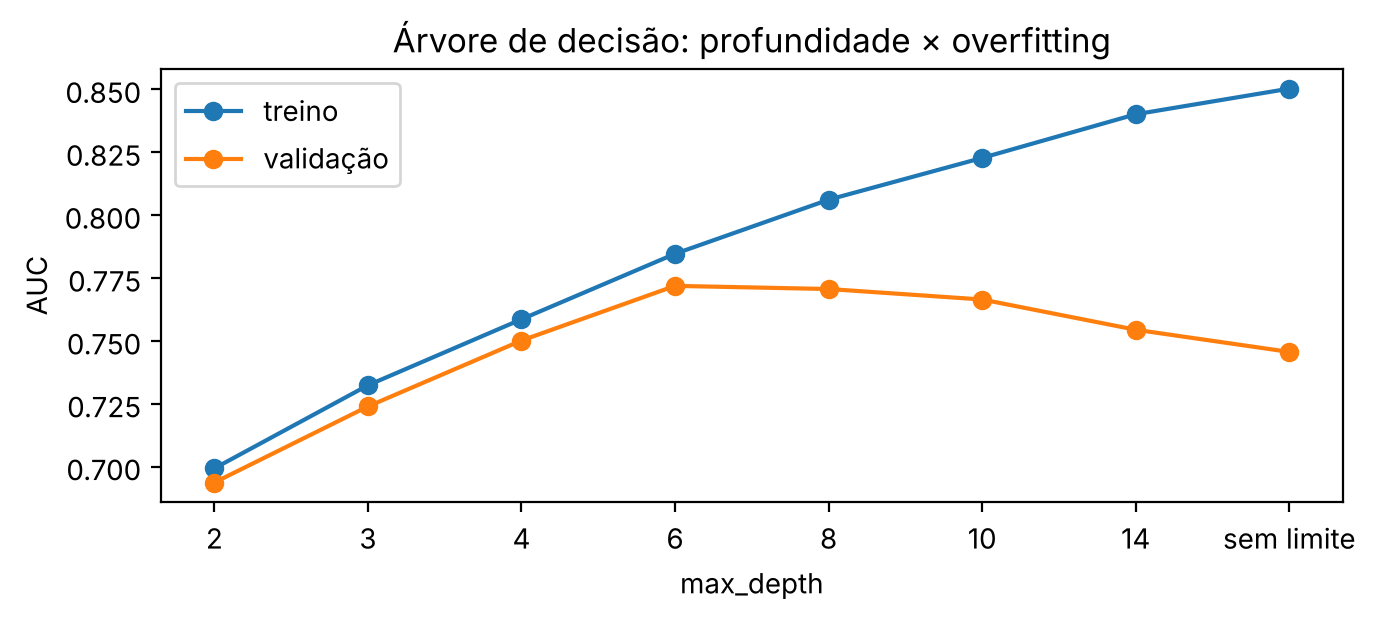

Profundidade escolhida pela validação: 6


,max_depth,AUC treino,AUC validação
0,2,0.699,0.694
1,3,0.732,0.724
2,4,0.759,0.750
3,6,0.785,0.772
4,8,0.806,0.771
5,10,0.823,0.766
6,14,0.840,0.754
7,sem limite,0.850,0.746


In [8]:
linhas = []
for prof in [2, 3, 4, 6, 8, 10, 14, None]:
    m = pipeline(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=30, random_state=SEED)).fit(X_tr, y_tr)
    linhas.append({"max_depth": "sem limite" if prof is None else prof,
                   "AUC treino": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]),
                   "AUC validação": roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
curva = pd.DataFrame(linhas)
PROF_ARVORE = curva.loc[curva["AUC validação"].idxmax(), "max_depth"]
PROF_ARVORE = None if PROF_ARVORE == "sem limite" else int(PROF_ARVORE)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(curva["max_depth"].astype(str), curva["AUC treino"], "o-", label="treino")
ax.plot(curva["max_depth"].astype(str), curva["AUC validação"], "o-", label="validação")
ax.set_xlabel("max_depth"); ax.set_ylabel("AUC"); ax.set_title("Árvore de decisão: profundidade × overfitting")
ax.legend(); plt.tight_layout(); plt.savefig(SAIDA / "curva_arvore.png", dpi=120); plt.show()
print("Profundidade escolhida pela validação:", PROF_ARVORE)
curva.round(3)

### 3.3 Modelos comparados
| Família | Modelo | Por que entra |
|---|---|---|
| Baseline | **Chute: todo mundo gosta** | o "palpite" que qualquer modelo precisa superar |
| Baseline | **Popularidade** (média do restaurante até a data) | é a ordenação atual dos apps (Canvas, bloco 8) |
| Linear | **Regressão logística** | simples e interpretável (navalha de Ockham) |
| Árvore | **Árvore de decisão** | regras legíveis, explica a recomendação (LGPD) |
| Ensemble | **Random forest** | muitas árvores, menos variância |
| Ensemble | **Gradient boosting** | árvores em sequência corrigindo o erro anterior |
| Vizinhos | **KNN** (k = 50) | "pessoas e restaurantes parecidos"; exige escala |

In [9]:
class Popularidade:
    # baseline: probabilidade = média suavizada do restaurante até a data, levada para 0-1
    def fit(self, X, y): return self
    def predict_proba(self, X):
        p = ((X["rest_media_prev"].to_numpy() - 1) / 4).clip(0, 1)
        return np.c_[1 - p, p]


modelos = {
    "Chute: todo mundo gosta": pipeline(DummyClassifier(strategy="prior")),
    "Popularidade (baseline)": Popularidade(),
    "Regressão logística": pipeline(LogisticRegression(max_iter=3000)),
    "Árvore de decisão": pipeline(DecisionTreeClassifier(max_depth=PROF_ARVORE, min_samples_leaf=30, random_state=SEED)),
    "Random forest": pipeline(RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=20,
                                                     n_jobs=-1, random_state=SEED)),
    "Gradient boosting": pipeline(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                                 max_leaf_nodes=31, random_state=SEED)),
    "KNN (k=50)": pipeline(KNeighborsClassifier(n_neighbors=50, weights="distance")),
}

proba_va, proba_te = {}, {}
for nome, m in modelos.items():
    if nome.startswith("KNN") and len(X_tr) > 60_000:   # KNN guarda o treino inteiro: amostra para caber no tempo
        a = X_tr.sample(60_000, random_state=SEED).index
        m.fit(X_tr.loc[a], y_tr.loc[a])
    else:
        m.fit(X_tr, y_tr)
    proba_va[nome] = m.predict_proba(X_va)[:, 1]
    proba_te[nome] = m.predict_proba(X_te)[:, 1]
    print(f"{nome:28s} AUC validação = {roc_auc_score(y_va, proba_va[nome]):.3f}")

Chute: todo mundo gosta      AUC validação = 0.500
Popularidade (baseline)      AUC validação = 0.682


Regressão logística          AUC validação = 0.787


Árvore de decisão            AUC validação = 0.772


Random forest                AUC validação = 0.792


Gradient boosting            AUC validação = 0.795


KNN (k=50)                   AUC validação = 0.759


### 3.4 Limiar de decisão pelo custo do erro
O modelo devolve uma probabilidade; a **decisão** de recomendar depende do limiar. Como o falso positivo é o erro
caro, escolhemos, **na validação**, o limiar que maximiza o **F0,5** (pesa a precisão 2 vezes mais que o recall).
O mesmo limiar é depois aplicado ao teste, sem reajuste.

Para o "chute" o limiar não muda nada: ele recomenda tudo.

In [10]:
def melhor_limiar(y, p, beta=0.5):
    grade = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
    if len(grade) < 2:                          # modelo constante (chute)
        return 0.0
    f = [fbeta_score(y, (p >= t).astype(int), beta=beta, zero_division=0) for t in grade]
    return float(grade[int(np.argmax(f))])

LIMIAR = {nome: melhor_limiar(y_va, p) for nome, p in proba_va.items()}
pd.Series(LIMIAR, name="limiar escolhido na validação").round(3).to_frame()

,limiar escolhido na validação
Chute: todo mundo gosta,0.000
Popularidade (baseline),0.738
Regressão logística,0.740
Árvore de decisão,0.728
Random forest,0.698
Gradient boosting,0.708
KNN (k=50),0.680


## 4. Evaluation no teste: acertos, falsos positivos e falsos negativos

Leitura da matriz de confusão para o Concierge (positivo = "recomendar, a pessoa vai gostar"):

| | Gostou de fato (nota ≥ 4) | Não gostou (nota ≤ 3) |
|---|---|---|
| **Modelo recomendou** | Verdadeiro positivo ✅ | **Falso positivo** ❌ pedido ruim, cliente perdido |
| **Modelo não recomendou** | **Falso negativo** ⚠️ oportunidade perdida | Verdadeiro negativo ✅ |

Duas formas de ler os percentuais (as duas estão na tabela):
- **% do total:** fatia de todas as avaliações do teste que caiu em cada célula; *acertos* = VP + VN.
- **Taxa:** taxa de falso positivo = FP ÷ todos que **não gostaram** (de cada 100 experiências ruins, quantas o modelo
  teria recomendado); taxa de falso negativo = FN ÷ todos que **gostaram**.

In [11]:
def avaliar(y, p, limiar):
    pred = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    n = tn + fp + fn + tp
    return {
        "Acertos (% do total)": 100 * (tp + tn) / n,
        "Falso positivo (% do total)": 100 * fp / n,
        "Falso negativo (% do total)": 100 * fn / n,
        "VP (% do total)": 100 * tp / n,
        "VN (% do total)": 100 * tn / n,
        "Taxa de FP (FP ÷ não gostou)": 100 * fp / (fp + tn),
        "Taxa de FN (FN ÷ gostou)": 100 * fn / (fn + tp),
        "Precisão": 100 * precision_score(y, pred, zero_division=0),
        "Recall": 100 * recall_score(y, pred, zero_division=0),
        "AUC": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5,
    }

resultado = pd.DataFrame({nome: avaliar(y_te, proba_te[nome], LIMIAR[nome]) for nome in modelos}).T
resultado["Limiar"] = pd.Series(LIMIAR)
resultado = resultado.sort_values("AUC", ascending=False)
resultado.to_csv(SAIDA / "metricas_teste.csv", float_format="%.3f")

cols_show = ["Acertos (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)",
             "Taxa de FP (FP ÷ não gostou)", "Taxa de FN (FN ÷ gostou)", "Precisão", "Recall", "AUC", "Limiar"]
(resultado[cols_show].style
 .format({c: "{:.1f}%" for c in cols_show[:7]} | {"AUC": "{:.3f}", "Limiar": "{:.3f}"})
 .background_gradient(subset=["Falso positivo (% do total)", "Taxa de FP (FP ÷ não gostou)"], cmap="Reds")
 .background_gradient(subset=["Acertos (% do total)", "AUC"], cmap="Greens"))

,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Taxa de FP (FP ÷ não gostou),Taxa de FN (FN ÷ gostou),Precisão,Recall,AUC,Limiar
Gradient boosting,74.8%,8.6%,16.6%,36.8%,21.6%,87.4%,78.4%,0.796,0.708
Random forest,75.2%,9.3%,15.5%,39.6%,20.3%,86.8%,79.7%,0.788,0.698
Regressão logística,73.0%,8.4%,18.5%,35.9%,24.2%,87.3%,75.8%,0.781,0.740
Árvore de decisão,73.0%,8.6%,18.4%,36.6%,24.1%,87.1%,75.9%,0.775,0.728
KNN (k=50),75.2%,11.7%,13.1%,49.8%,17.1%,84.5%,82.9%,0.758,0.680
Popularidade (baseline),72.6%,14.2%,13.1%,60.6%,17.2%,81.7%,82.8%,0.684,0.738
Chute: todo mundo gosta,76.6%,23.4%,0.0%,100.0%,0.0%,76.6%,100.0%,0.500,0.000


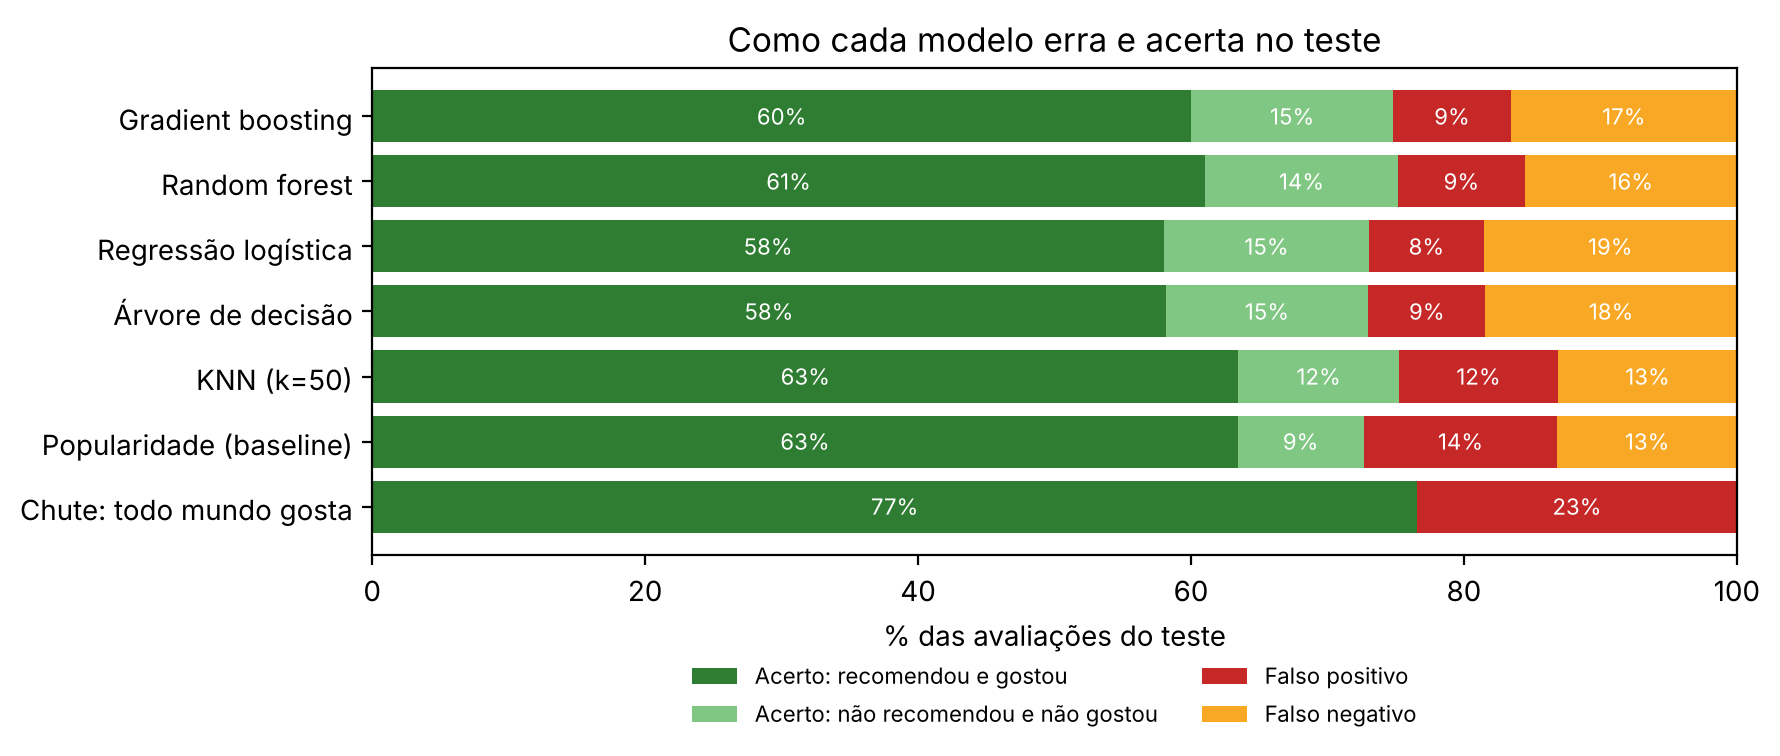

In [12]:
# Composição do teste por modelo: acertos, FP e FN somam 100%
comp = resultado[["VP (% do total)", "VN (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)"]]
fig, ax = plt.subplots(figsize=(9, 4))
esq = np.zeros(len(comp))
cores = {"VP (% do total)": "#2E7D32", "VN (% do total)": "#81C784",
         "Falso positivo (% do total)": "#C62828", "Falso negativo (% do total)": "#F9A825"}
rotulos = {"VP (% do total)": "Acerto: recomendou e gostou", "VN (% do total)": "Acerto: não recomendou e não gostou",
           "Falso positivo (% do total)": "Falso positivo", "Falso negativo (% do total)": "Falso negativo"}
for c in comp.columns:
    ax.barh(comp.index, comp[c], left=esq, color=cores[c], label=rotulos[c])
    for i, (v, e) in enumerate(zip(comp[c], esq)):
        if v >= 4:
            ax.text(e + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
    esq += comp[c].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% das avaliações do teste")
ax.set_title("Como cada modelo erra e acerta no teste")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(SAIDA / "composicao_erros.png", dpi=120); plt.show()

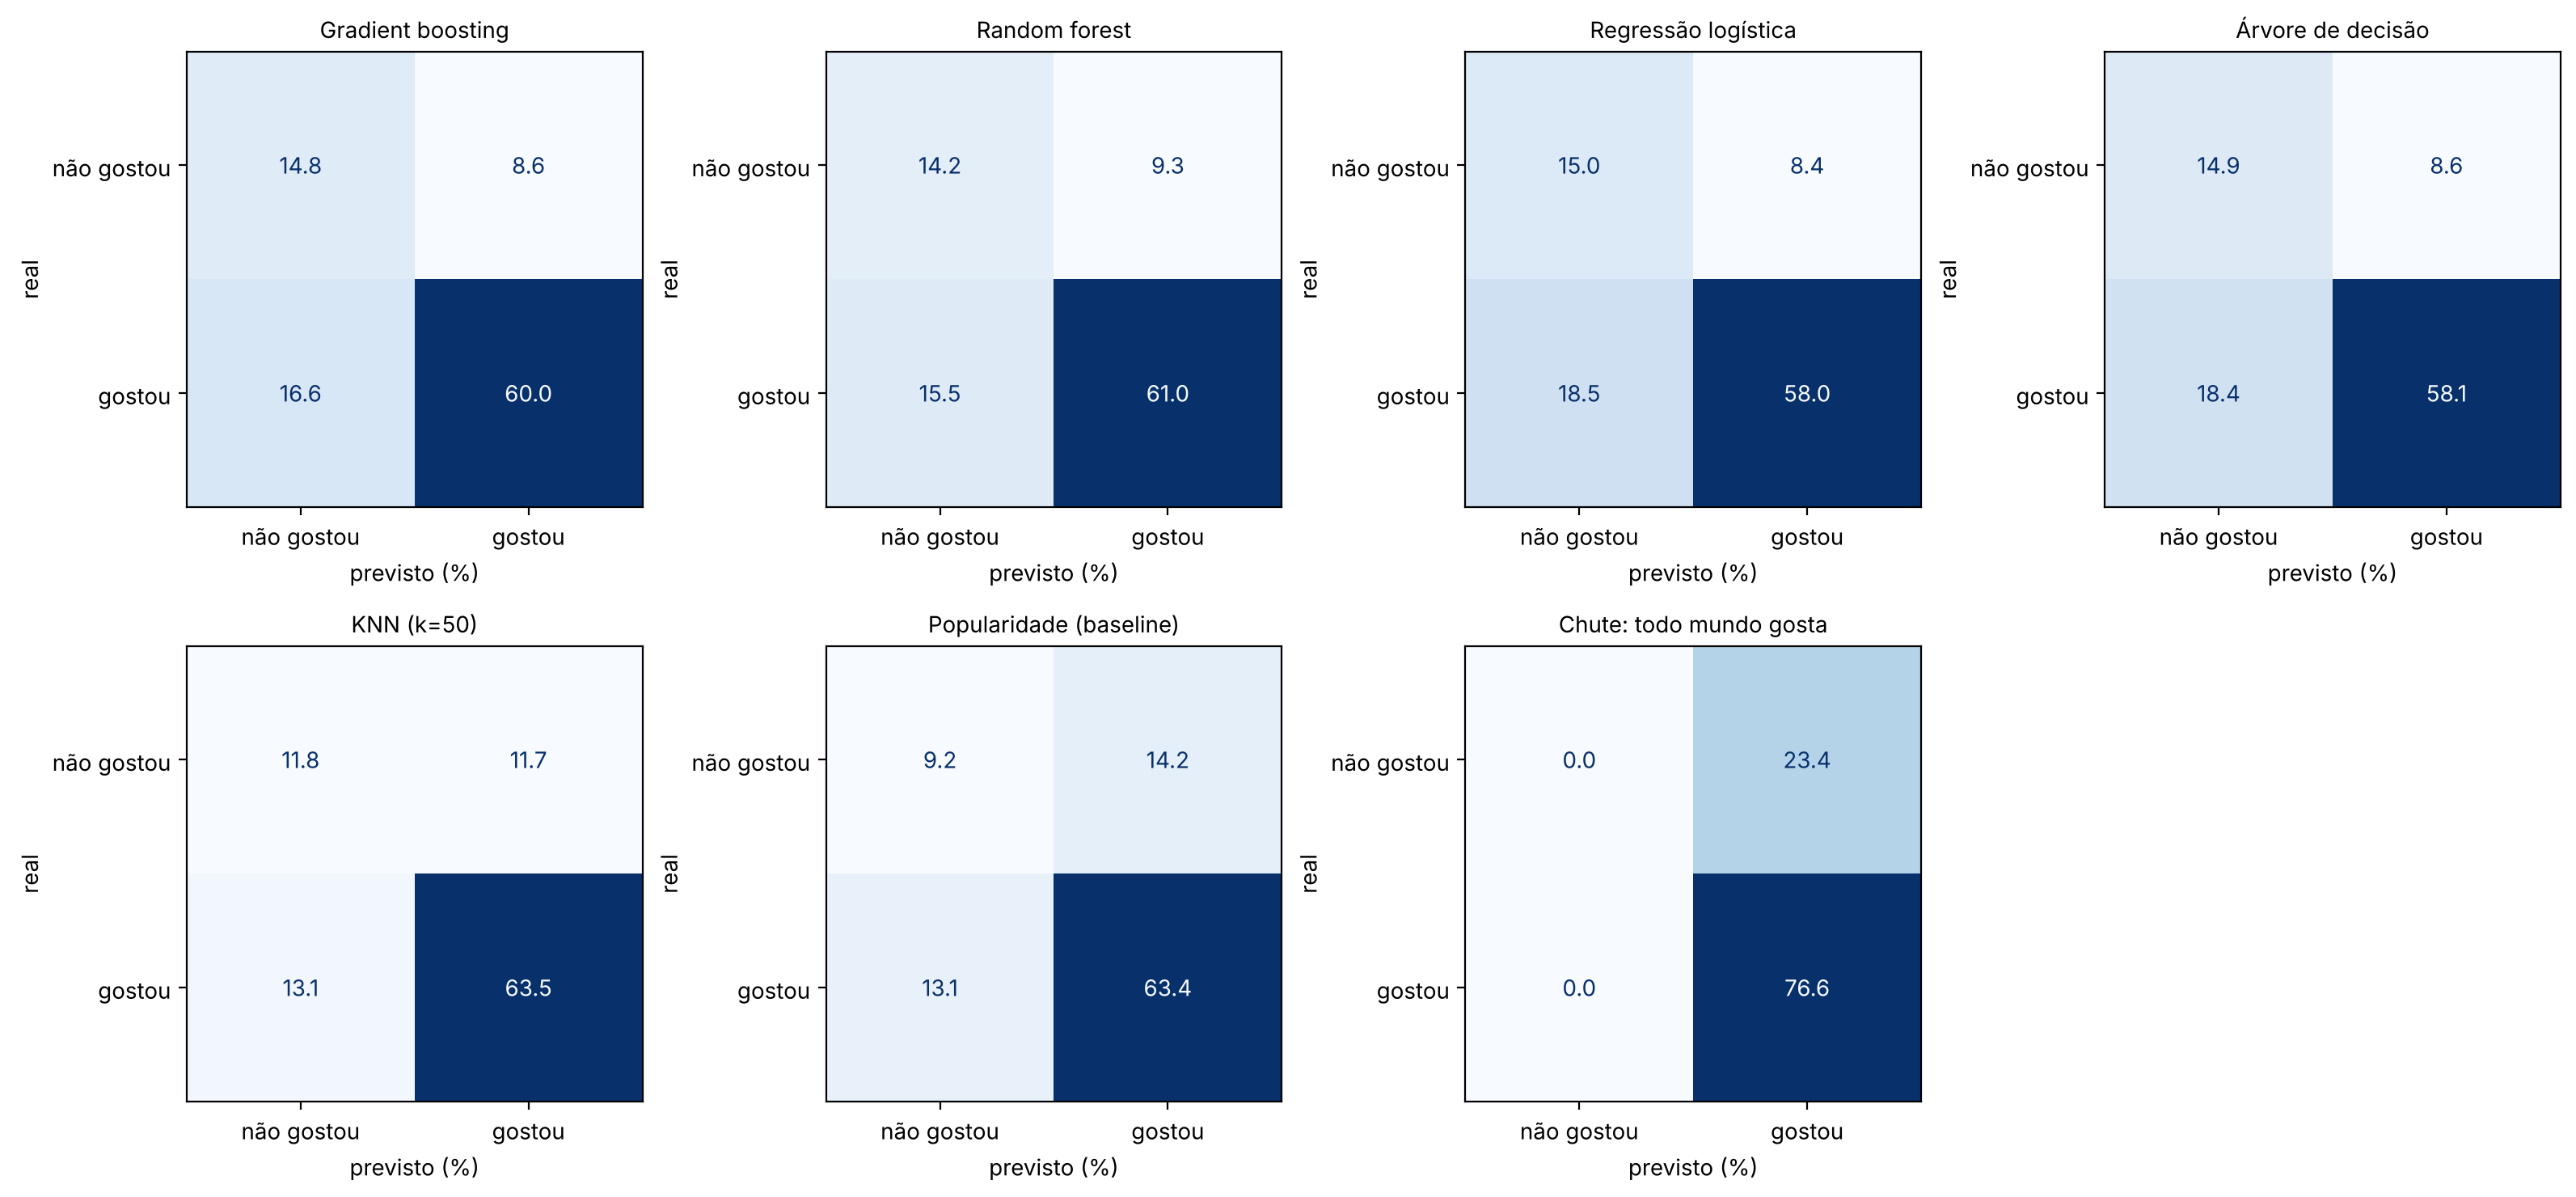

In [13]:
# Matrizes de confusão (normalizadas pelo total do teste)
nomes = list(resultado.index)
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, nome in zip(axes.ravel(), nomes):
    pred = (proba_te[nome] >= LIMIAR[nome]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0, 1], normalize="all") * 100,
                           display_labels=["não gostou", "gostou"]).plot(ax=ax, colorbar=False, values_format=".1f",
                                                                         cmap="Blues")
    ax.set_title(nome, fontsize=10); ax.set_xlabel("previsto (%)"); ax.set_ylabel("real")
for ax in axes.ravel()[len(nomes):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(SAIDA / "matrizes_confusao.png", dpi=120); plt.show()

### 4.0 O efeito do limiar no melhor modelo
O ranking (AUC) é o mesmo; o que muda com o limiar é a **decisão**. Subir o limiar troca falso positivo (caro) por
falso negativo (barato). O limiar 0,5 é o padrão do `predict()`; o F0,5 é a nossa escolha pelo custo do erro.

,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Precisão,Recall
limiar 0.50,79.9,15.7,4.4,82.1,94.3
"limiar 0.71 (F0,5)",74.8,8.6,16.6,87.4,78.4
limiar 0.85,61.0,3.2,35.8,92.8,53.2


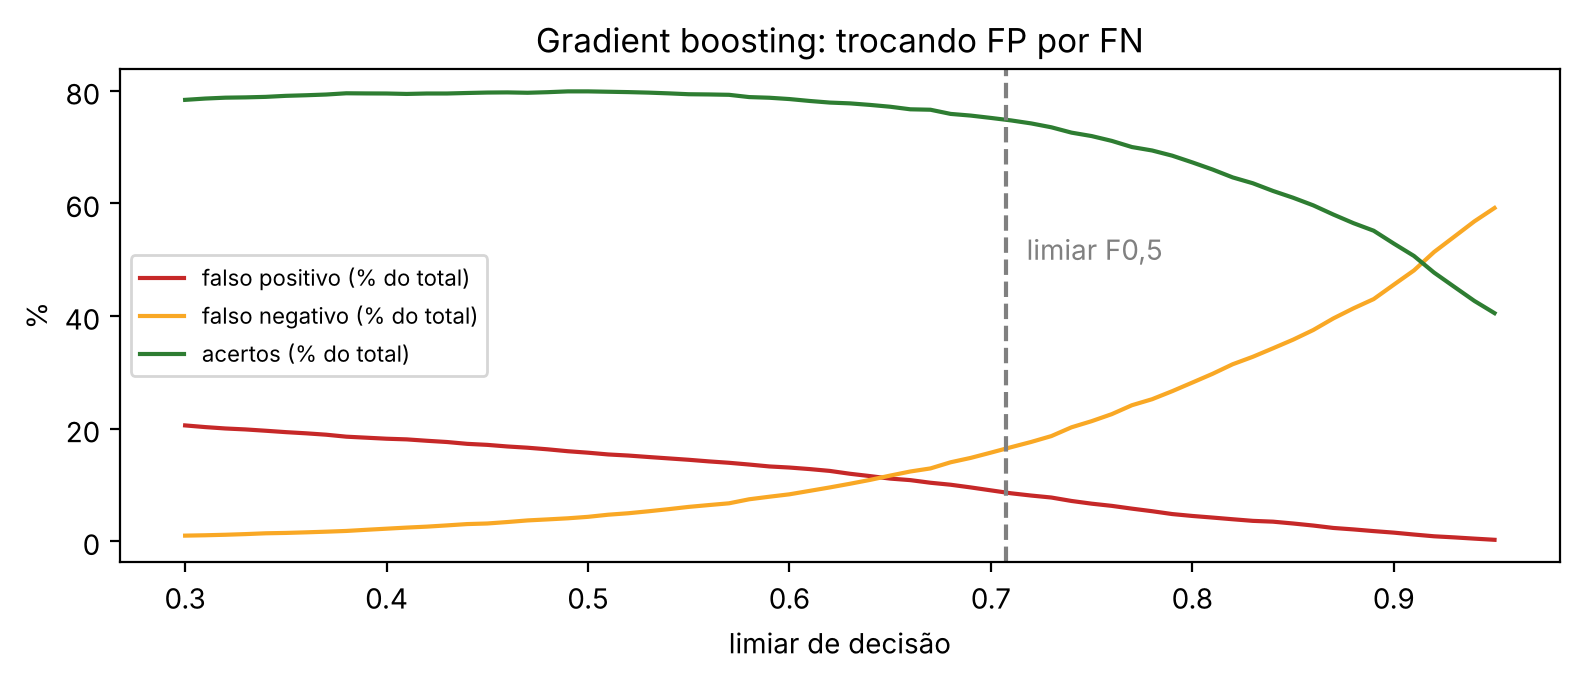

In [14]:
MELHOR = resultado.drop(["Chute: todo mundo gosta", "Popularidade (baseline)"])["AUC"].idxmax()
p_best = proba_te[MELHOR]
tab = pd.DataFrame({f"limiar {t:.2f}" + (" (F0,5)" if t == LIMIAR[MELHOR] else ""): avaliar(y_te, p_best, t)
                    for t in [0.5, LIMIAR[MELHOR], 0.85]}).T
display(tab[["Acertos (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)",
             "Precisão", "Recall"]].round(1))

grade = np.linspace(0.3, 0.95, 66)
curvas = pd.DataFrame([avaliar(y_te, p_best, t) for t in grade], index=grade)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(grade, curvas["Falso positivo (% do total)"], color="#C62828", label="falso positivo (% do total)")
ax.plot(grade, curvas["Falso negativo (% do total)"], color="#F9A825", label="falso negativo (% do total)")
ax.plot(grade, curvas["Acertos (% do total)"], color="#2E7D32", label="acertos (% do total)")
ax.axvline(LIMIAR[MELHOR], ls="--", color="gray"); ax.text(LIMIAR[MELHOR] + 0.01, 50, "limiar F0,5", color="gray")
ax.set_xlabel("limiar de decisão"); ax.set_ylabel("%"); ax.set_title(f"{MELHOR}: trocando FP por FN")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(SAIDA / "efeito_limiar.png", dpi=120); plt.show()

### 4.1 Por segmento: usuários novos × ativos (BU, 1.3)
A maior parte do teste é de usuários sem histórico (*cold start*). O ganho do perfil só aparece se olharmos os grupos
separados. Comparamos o melhor modelo com o baseline de popularidade.

In [15]:
novo = X_te["usuario_novo"].to_numpy() == 1

seg = []
for nome in [MELHOR, "Popularidade (baseline)"]:
    for rot, m in [("usuários novos", novo), ("usuários ativos", ~novo)]:
        r = avaliar(y_te.to_numpy()[m], proba_te[nome][m], LIMIAR[nome])
        seg.append({"modelo": nome, "segmento": rot, "n": int(m.sum()),
                    **{k: r[k] for k in ["Acertos (% do total)", "Falso positivo (% do total)",
                                         "Falso negativo (% do total)", "Taxa de FP (FP ÷ não gostou)",
                                         "Precisão", "AUC"]}})
seg = pd.DataFrame(seg).set_index(["modelo", "segmento"])
a_novo, a_pop_novo = seg.loc[(MELHOR, "usuários novos"), "AUC"], seg.loc[("Popularidade (baseline)", "usuários novos"), "AUC"]
a_ativo, a_pop_ativo = seg.loc[(MELHOR, "usuários ativos"), "AUC"], seg.loc[("Popularidade (baseline)", "usuários ativos"), "AUC"]
print(f"Ganho de AUC sobre a popularidade -> ativos: {a_ativo - a_pop_ativo:+.3f} | novos: {a_novo - a_pop_novo:+.3f}")
if a_novo - a_pop_novo < 0.01:
    print("Sem histórico, o modelo não supera a popularidade: o ganho vem do perfil. "
          "É o argumento para o questionário preencher esse perfil no cold start.")
seg.round({c: 1 for c in seg.columns if c != "AUC"} | {"AUC": 3})

Ganho de AUC sobre a popularidade -> ativos: +0.136 | novos: -0.003
Sem histórico, o modelo não supera a popularidade: o ganho vem do perfil. É o argumento para o questionário preencher esse perfil no cold start.


n  Acertos (% do total)  Falso positivo (% do total)  Falso negativo (% do total)  Taxa de FP (FP ÷ não gostou)  \
modelo                  segmento                                                                                                                              
Gradient boosting       usuários novos   1609                  71.9                         11.6                         16.5                          54.5   
                        usuários ativos  6090                  75.6                          7.8                         16.6                          32.7   
Popularidade (baseline) usuários novos   1609                  73.0                         12.4                         14.7                          58.4   
                        usuários ativos  6090                  72.6                         14.7                         12.7                          61.2   

                                         Precisão    AUC  
modelo                  segmento                          
Gradient boosting       usuários novos       84.3  0.705  
                        usuários ativos      88.3  0.814  
Popularidade (baseline) usuários novos       83.8  0.708  
                        usuários ativos      81.1  0.678

### 4.2 Interpretação: o que a árvore aprendeu
A árvore é o modelo mais fácil de explicar ao usuário ("indicado porque você costuma pedir essa culinária e a casa é
bem avaliada"). Abaixo, os 3 primeiros níveis e a importância das variáveis na random forest e na árvore.

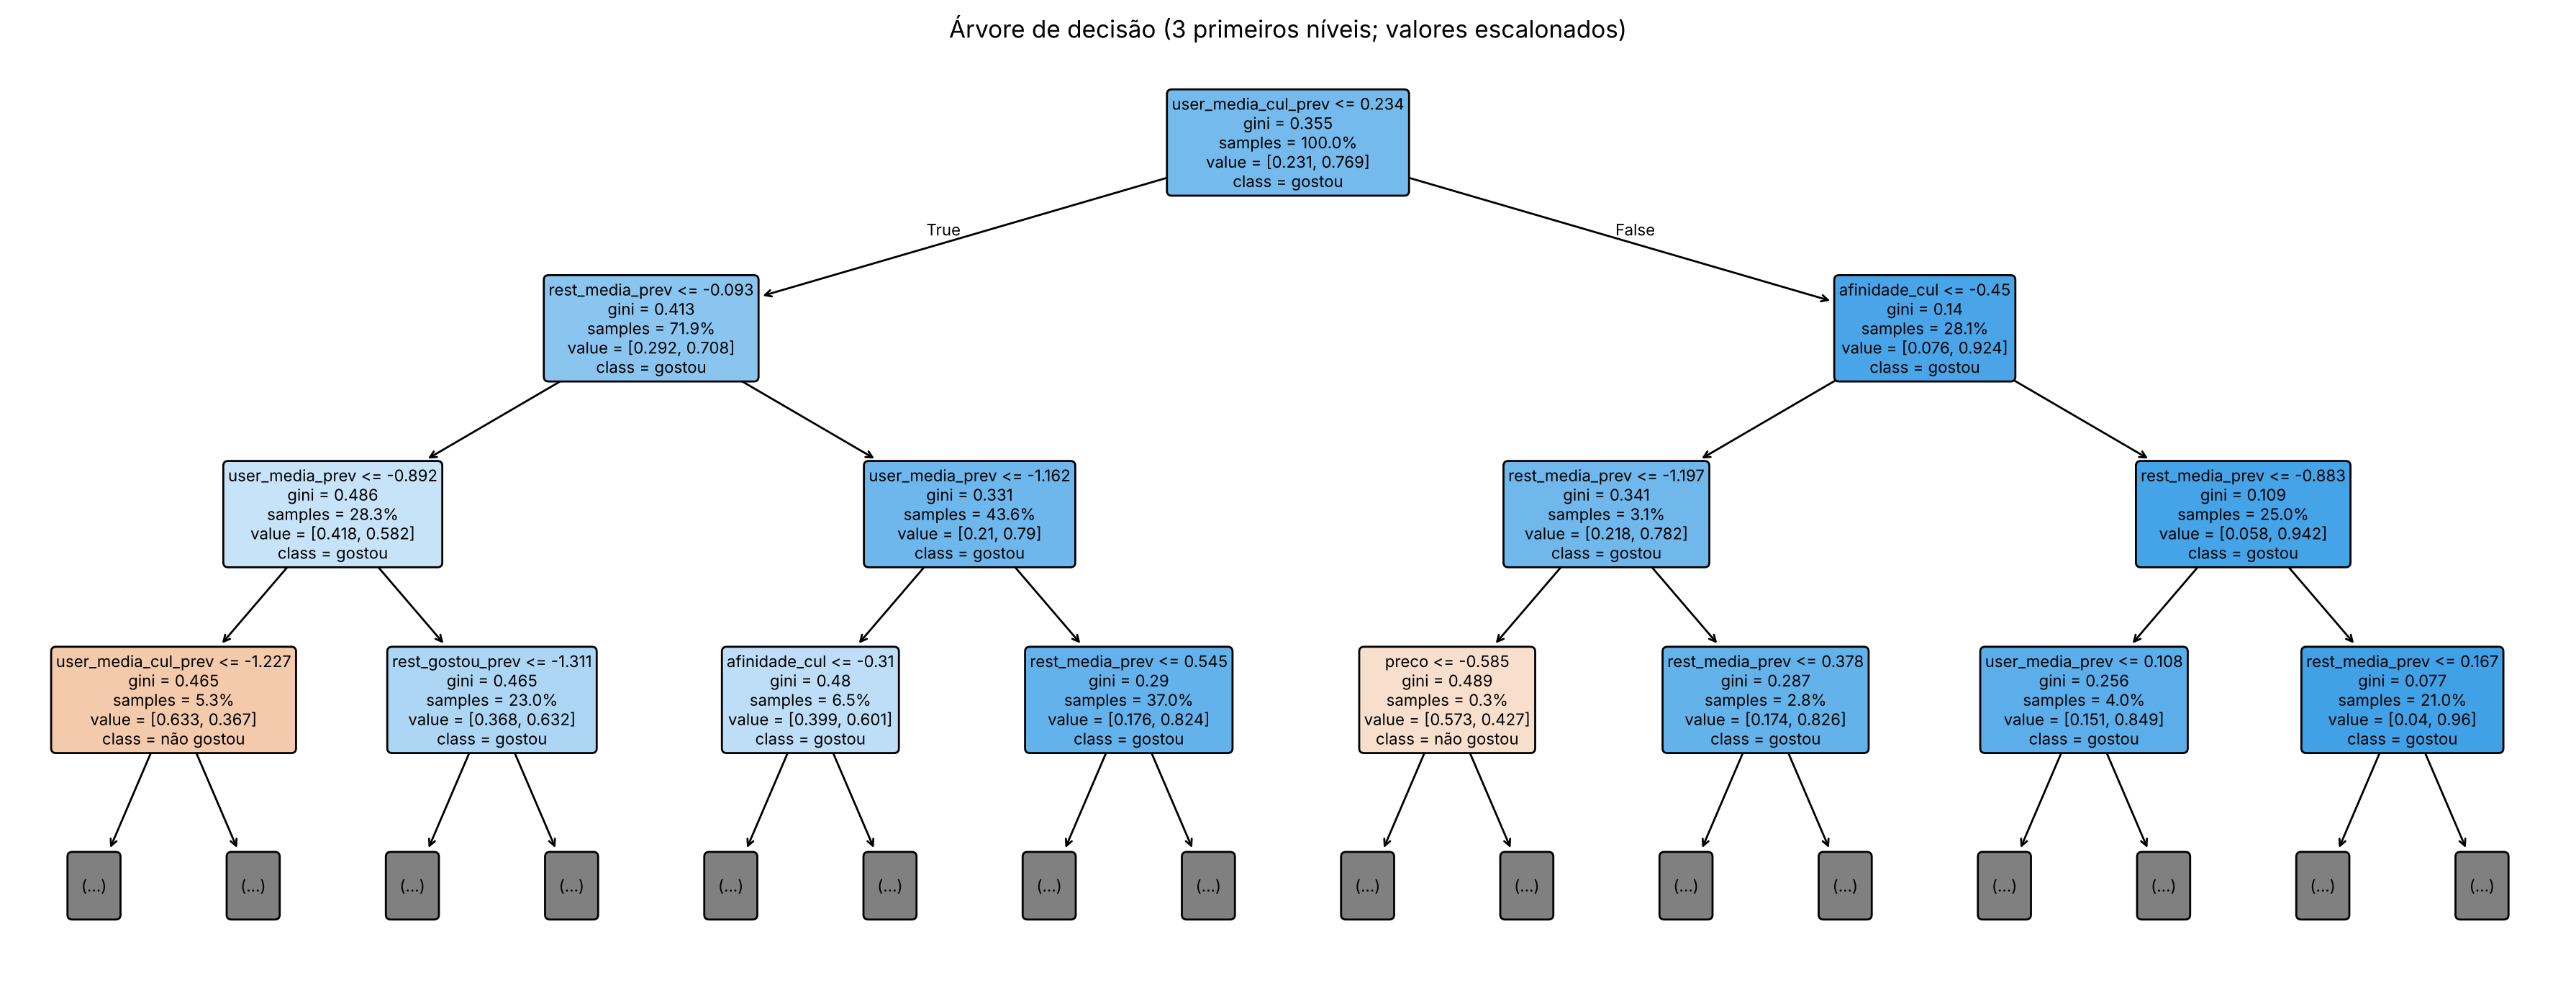

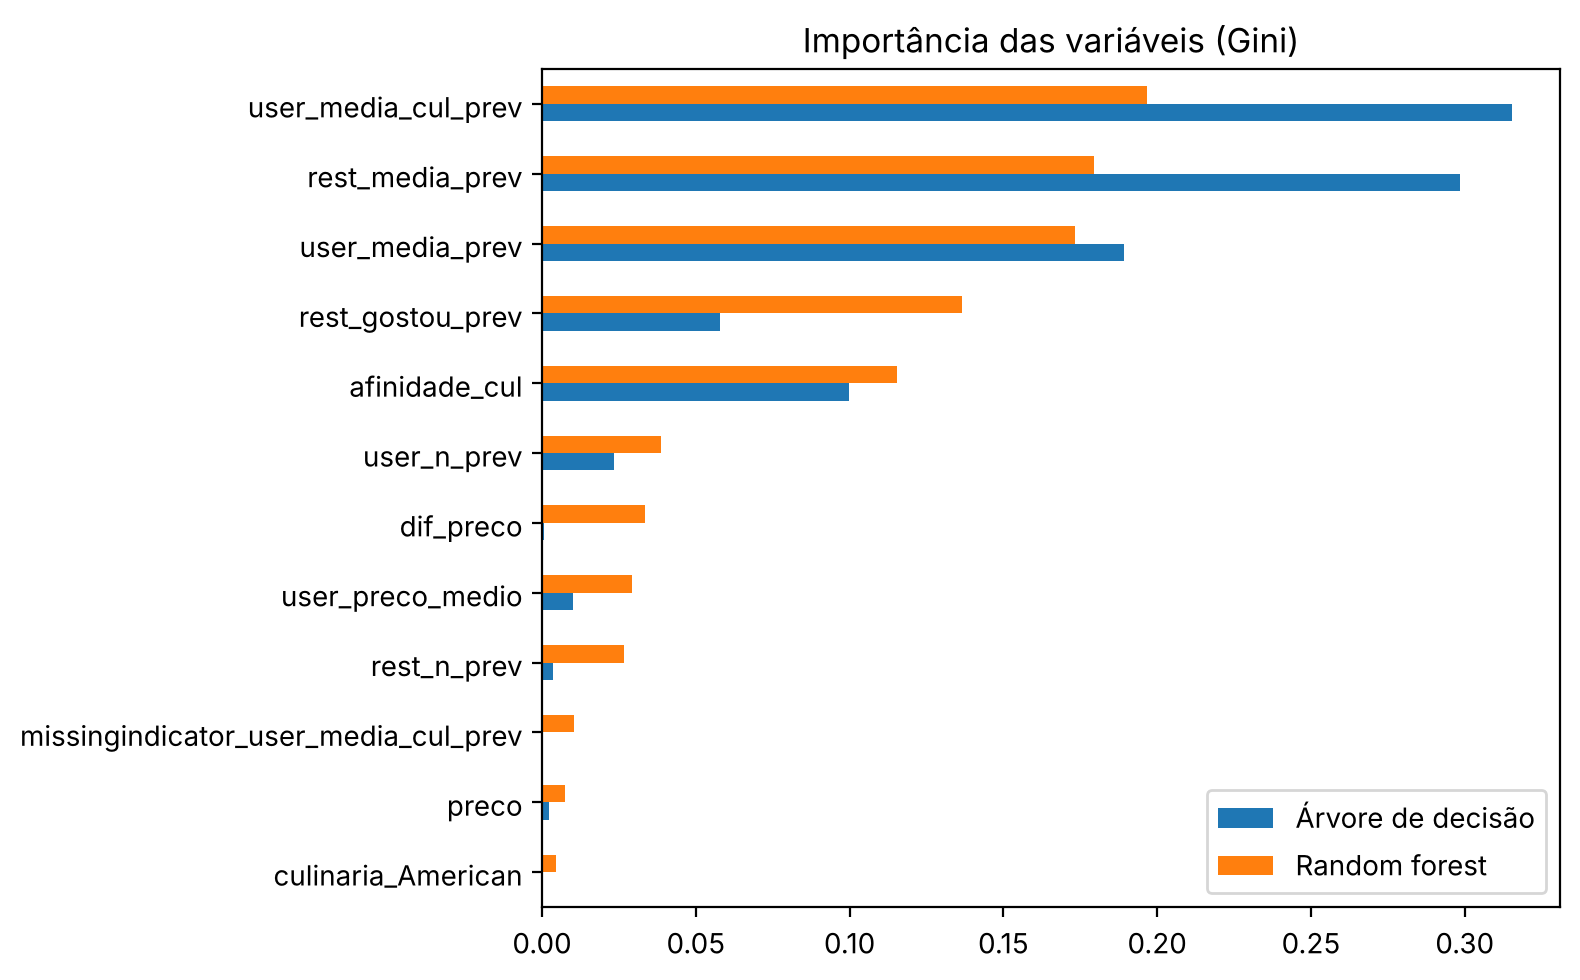

In [16]:
arv = modelos["Árvore de decisão"]
nomes_feat = arv.named_steps["pre"].get_feature_names_out()
nomes_feat = [n.replace("num__", "").replace("cat__", "") for n in nomes_feat]

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arv.named_steps["clf"], max_depth=3, feature_names=nomes_feat, class_names=["não gostou", "gostou"],
          filled=True, impurity=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Árvore de decisão (3 primeiros níveis; valores escalonados)")
plt.tight_layout(); plt.savefig(SAIDA / "arvore.png", dpi=110); plt.show()

imp = pd.DataFrame({
    "Árvore de decisão": arv.named_steps["clf"].feature_importances_,
    "Random forest": modelos["Random forest"].named_steps["clf"].feature_importances_,
}, index=nomes_feat).sort_values("Random forest", ascending=False).head(12)
imp.iloc[::-1].plot.barh(figsize=(8, 5), title="Importância das variáveis (Gini)")
plt.tight_layout(); plt.savefig(SAIDA / "importancias.png", dpi=120); plt.show()

### 4.3 Decisão (CRISP-DM: aprovar, voltar à Fase 3 ou à Fase 1)
A célula abaixo escreve a conclusão a partir dos números, para que ela continue correta quando o notebook rodar com o
Yelp real.

In [17]:
r_m, r_p, r_c = resultado.loc[MELHOR], resultado.loc["Popularidade (baseline)"], resultado.loc["Chute: todo mundo gosta"]
print(f"Fonte dos dados: {FONTE}")
print(f"Melhor modelo (AUC no teste): {MELHOR}  ->  AUC {r_m['AUC']:.3f} vs popularidade {r_p['AUC']:.3f}")
print(f"Limiar de decisão: {r_m['Limiar']:.3f} (F0,5 na validação)\n")
print(f"{'':32s}{'acertos':>9s}{'FP':>8s}{'FN':>8s}{'precisão':>10s}")
for n, r in [(MELHOR, r_m), ("Popularidade (baseline)", r_p), ("Chute: todo mundo gosta", r_c)]:
    print(f"{n:32s}{r['Acertos (% do total)']:8.1f}%{r['Falso positivo (% do total)']:7.1f}%"
          f"{r['Falso negativo (% do total)']:7.1f}%{r['Precisão']:9.1f}%")
ganho_prec = r_m["Precisão"] - r_c["Precisão"]
corte_fp = r_c["Falso positivo (% do total)"] - r_m["Falso positivo (% do total)"]
print(f"\nFrente ao chute, o {MELHOR} reduz os falsos positivos em {corte_fp:.1f} p.p. do total e eleva a precisão "
      f"em {ganho_prec:.1f} p.p.;\no custo é deixar de recomendar parte do que a pessoa gostaria (FN), o erro barato.")
veredito = "APROVAR para a Fase 5" if r_m["AUC"] > r_p["AUC"] and r_m["Precisão"] > r_p["Precisão"] else \
           "VOLTAR à Fase 3 (não supera a popularidade)"
print("Decisão:", veredito)

Fonte dos dados: amostra sintética (esquema do Yelp)
Melhor modelo (AUC no teste): Gradient boosting  ->  AUC 0.796 vs popularidade 0.684
Limiar de decisão: 0.708 (F0,5 na validação)

                                  acertos      FP      FN  precisão
Gradient boosting                   74.8%    8.6%   16.6%     87.4%
Popularidade (baseline)             72.6%   14.2%   13.1%     81.7%
Chute: todo mundo gosta             76.6%   23.4%    0.0%     76.6%

Frente ao chute, o Gradient boosting reduz os falsos positivos em 14.8 p.p. do total e eleva a precisão em 10.9 p.p.;
o custo é deixar de recomendar parte do que a pessoa gostaria (FN), o erro barato.
Decisão: APROVAR para a Fase 5


### 4.4 KPI técnico do BU: RMSE da nota
O BU definiu a régua como **RMSE menor que o da lista por popularidade** (média do restaurante). Aqui a mesma base,
o mesmo corte temporal e os mesmos atributos alimentam um *gradient boosting* de regressão, comparado com três
referências: média global, popularidade e popularidade + viés do usuário. O resultado é reportado também para usuários
novos e ativos, porque o BU pediu o *cold start* à parte.

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor


def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))


yr_tr = df.loc[df["periodo"] == "treino", "stars"]
yr_te = df.loc[df["periodo"] == "teste", "stars"].to_numpy()
reg = pipeline(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)).fit(X_tr, yr_tr)
prev = {
    "Média global (treino)": np.full(len(yr_te), MU),
    "Popularidade (média do restaurante)": X_te["rest_media_prev"].to_numpy(),
    "Popularidade + viés do usuário": (X_te["rest_media_prev"] + (X_te["user_media_prev"] - MU).fillna(0)).clip(1, 5).to_numpy(),
    "Gradient boosting (regressão)": reg.predict(X_te).clip(1, 5),
}
novo_te = X_te["usuario_novo"].to_numpy() == 1
tab_rmse = pd.DataFrame({n: {"RMSE (todos)": rmse(yr_te, p), "RMSE (usuários novos)": rmse(yr_te[novo_te], p[novo_te]),
                             "RMSE (usuários ativos)": rmse(yr_te[~novo_te], p[~novo_te])} for n, p in prev.items()}).T
tab_rmse.to_csv(SAIDA / "rmse_teste.csv", float_format="%.3f")
meta = tab_rmse.loc["Popularidade (média do restaurante)", "RMSE (todos)"]
ganho = meta - tab_rmse.loc["Gradient boosting (regressão)", "RMSE (todos)"]
print(f"Meta do BU: RMSE abaixo de {meta:.3f} (popularidade). Modelo: {'cumpre' if ganho > 0 else 'não cumpre'} "
      f"({ganho:+.3f}).")
tab_rmse.round(3)

Meta do BU: RMSE abaixo de 1.048 (popularidade). Modelo: cumpre (+0.104).


,RMSE (todos),RMSE (usuários novos),RMSE (usuários ativos)
Média global (treino),1.108,1.088,1.113
Popularidade (média do restaurante),1.048,1.019,1.055
Popularidade + viés do usuário,1.008,1.019,1.006
Gradient boosting (regressão),0.944,1.023,0.921


## 5. Uso: top 5 a partir do questionário
O usuário novo responde à árvore do app (modo, culinárias, faixa de preço). Essas respostas preenchem os atributos de
**perfil** (`afinidade_cul`, `user_preco_medio`, `dif_preco`) como se ele tivesse 3 avaliações, que é o protocolo do
*questionário simulado* do BU. As médias de notas do usuário ficam vazias (imputadas), porque ele ainda não avaliou
nada. Distância e raio entram como filtro, não no modelo.

Regra de negócio: só entra no top quem passa do limiar. **Se menos de 5 passarem, o top fica menor**.

In [19]:
# Estado atual de cada restaurante: todas as avaliações até hoje (legítimo na hora de recomendar)
hist = df.groupby("business_id").agg(n=("stars", "size"), soma=("stars", "sum"), gostou=("gostou", "sum"))
atual = rest.set_index("business_id").join(hist).fillna({"n": 0, "soma": 0, "gostou": 0})
atual["rest_n_prev"] = atual["n"]
atual["rest_media_prev"] = (atual["soma"] + K_REST * MU) / (atual["n"] + K_REST)
atual["rest_gostou_prev"] = (atual["gostou"] + K_REST * P_GOSTOU) / (atual["n"] + K_REST)

modelo_final = modelos[MELHOR]


def recomendar(culinarias, faixa_preco, modo="pedir", top=5, n_perfil=3):
    cand = atual[atual["is_open"] == 1].copy()
    cand = cand[cand["delivery"] == 1] if modo == "pedir" else cand[cand["reserva"] == 1]
    cand = cand[cand["preco"] <= faixa_preco]        # "até $$" é teto declarado: filtro, não preferência
    cand["user_n_prev"] = n_perfil
    cand["usuario_novo"] = 0
    cand["user_media_prev"] = np.nan             # ainda sem notas: imputado pelo pipeline
    cand["user_media_cul_prev"] = np.nan
    cand["user_preco_medio"] = float(faixa_preco)
    cand["dif_preco"] = (cand["preco"] - faixa_preco).abs()
    cand["afinidade_cul"] = np.where(cand["culinaria"].isin(culinarias), 1 / len(culinarias), 0.0)
    cand["prob_gostar"] = modelo_final.predict_proba(cand[NUM + CAT])[:, 1]
    ok = cand[cand["prob_gostar"] >= LIMIAR[MELHOR]].sort_values("prob_gostar", ascending=False).head(top)
    ok["por que"] = [("culinária que você escolheu" if c in culinarias else "fora das suas culinárias, mas muito bem avaliado")
                     + f", {'$' * int(p)}" for c, p in zip(ok["culinaria"], ok["preco"])]
    return ok[["nome", "culinaria", "preco", "rest_media_prev", "rest_n_prev", "prob_gostar", "por que"]].round(3)


print("Perfil: quer PEDIR, gosta de Japanese e Thai, até $$")
recomendar(["Japanese", "Thai"], faixa_preco=2, modo="pedir")

Perfil: quer PEDIR, gosta de Japanese e Thai, até $$


,nome,culinaria,preco,rest_media_prev,rest_n_prev,prob_gostar,por que
business_id,,,,,,,
b00428,Restaurante 428,Japanese,2.0,4.804,92.0,0.981,"culinária que você escolheu, $$"
b00070,Restaurante 70,Thai,2.0,4.671,66.0,0.978,"culinária que você escolheu, $$"
b00523,Restaurante 523,Vietnamese,2.0,4.726,34.0,0.978,"fora das suas culinárias, mas muito bem avalia..."
b00888,Restaurante 888,Burgers,1.0,4.720,33.0,0.975,"fora das suas culinárias, mas muito bem avalia..."
b00160,Restaurante 160,Mexican,2.0,4.749,54.0,0.975,"fora das suas culinárias, mas muito bem avalia..."


In [20]:
print("Perfil: quer SAIR, gosta de Italian e Steakhouses, até $$$")
recomendar(["Italian", "Steakhouses"], faixa_preco=3, modo="sair")

Perfil: quer SAIR, gosta de Italian e Steakhouses, até $$$


,nome,culinaria,preco,rest_media_prev,rest_n_prev,prob_gostar,por que
business_id,,,,,,,
b00859,Restaurante 859,Italian,3.0,4.694,49.0,0.980,"culinária que você escolheu, $$$"
b01040,Restaurante 1040,Steakhouses,3.0,4.783,27.0,0.980,"culinária que você escolheu, $$$"
b00176,Restaurante 176,Italian,2.0,4.764,92.0,0.976,"culinária que você escolheu, $$"
b01437,Restaurante 1437,Steakhouses,3.0,4.660,43.0,0.971,"culinária que você escolheu, $$$"
b00411,Restaurante 411,Mexican,2.0,4.859,97.0,0.967,"fora das suas culinárias, mas muito bem avalia..."


In [21]:
import joblib
joblib.dump({"modelo": modelo_final, "nome": MELHOR, "limiar": LIMIAR[MELHOR], "atributos": NUM + CAT,
             "mu": MU, "fonte": FONTE}, MODELOS / "concierge_reviews.joblib", compress=3)
print("Modelo em", (MODELOS / "concierge_reviews.joblib").relative_to(RAIZ), "(fica fora do Git)")
print("Figuras e tabelas em", SAIDA.relative_to(RAIZ))
for f in sorted(SAIDA.iterdir()):
    print("  ", f.name)

Modelo em models/concierge_reviews.joblib (fica fora do Git)
Figuras e tabelas em reports/03b_reviews
   arvore.png
   composicao_erros.png
   curva_arvore.png
   efeito_limiar.png
   importancias.png
   matrizes_confusao.png
   metricas_teste.csv
   rmse_teste.csv


## 6. Limites e próximos passos
- **Dados sintéticos:** se a fonte acima for a amostra, o sinal de gosto foi colocado pelo gerador. Os percentuais
  validam o código, não o produto. Com o Yelp real em `data/raw/`, rode de novo: nada no código muda.
- **Questionário:** nenhum usuário do Yelp respondeu ao questionário; o top 5 da seção 5 usa o perfil declarado como
  se fosse histórico. O app grava as respostas e o feedback, e o mesmo protocolo passa a medir o *cold start* de verdade.
- **Comparação com o 03a:** aqui a personalização vem da nota individual; no 03a, da preferência revelada (dicas).
  O app usa o 03a porque ele junta a guarda de qualidade e a localização; este notebook mostra se a nota individual
  acrescenta (AUC e RMSE contra a popularidade).
- **Pandemia:** o teste começa em 2020; a queda de avaliações e a mudança de hábito (mais delivery) entram no teste.
- **Responsible AI:** sem gênero, idade ou raça no modelo; cada recomendação vem com o "por quê" (LGPD). Cobertura e
  viés para populares estão no notebook 04.